In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import scipy.stats as stats
import sympy as sym
import matplotlib.pyplot as plt
import cvxpy as cv

Part A

In [2]:
golf = pd.read_csv("time_series_US_20031231-1800_20261013-2329.csv")
golf = golf[golf['Time'] <= '2025-09-01'].reset_index(drop=True) 
N = len(golf)                                   
y = golf['golf'].to_numpy(dtype=float)          
t = np.arange(1, N+1)

X = np.zeros((N, N+2))
X[:, 0] = 1
for i in range(1, N):
    X[:, i] = np.maximum(t - i, 0)
X[:, N]   = np.cos(2*np.pi*t/12)
X[:, N+1] = np.sin(2*np.pi*t/12)

print(N, X.shape)          
print(X[:5, :5])          
print(X[:13, -2:])        

261 (261, 263)
[[1. 0. 0. 0. 0.]
 [1. 1. 0. 0. 0.]
 [1. 2. 1. 0. 0.]
 [1. 3. 2. 1. 0.]
 [1. 4. 3. 2. 1.]]
[[ 8.66025404e-01  5.00000000e-01]
 [ 5.00000000e-01  8.66025404e-01]
 [ 6.12323400e-17  1.00000000e+00]
 [-5.00000000e-01  8.66025404e-01]
 [-8.66025404e-01  5.00000000e-01]
 [-1.00000000e+00  1.22464680e-16]
 [-8.66025404e-01 -5.00000000e-01]
 [-5.00000000e-01 -8.66025404e-01]
 [-1.83697020e-16 -1.00000000e+00]
 [ 5.00000000e-01 -8.66025404e-01]
 [ 8.66025404e-01 -5.00000000e-01]
 [ 1.00000000e+00 -2.44929360e-16]
 [ 8.66025404e-01  5.00000000e-01]]


In [3]:
K = 5
idx = np.arange(N)

D = np.ones(N+2)
D[:2] = 0       
D[N:] = 0         
D = np.diag(D)

lmbda = np.logspace(-3, 6, 91)

cv_error = []
for lam in lmbda:
    fold_error = []
    for k in range(K):
        test  = (idx % K == k)
        train = ~test
        X_train, y_train = X[train], y[train]
        X_test,  y_test  = X[test],  y[test]

        A = X_train.T @ X_train + lam * D
        b = X_train.T @ y_train
        beta_hat = np.linalg.solve(A, b)

        pred = X_test @ beta_hat
        fold_error.append(np.mean((y_test - pred)**2))
    cv_error.append(np.mean(fold_error))

best_i = np.argmin(cv_error)
best_lam = lmbda[best_i]
print(f"best lambda = {best_lam:.3g}  (grid index {best_i} of {len(lmbda)-1})")


best lambda = 1.26  (grid index 31 of 90)


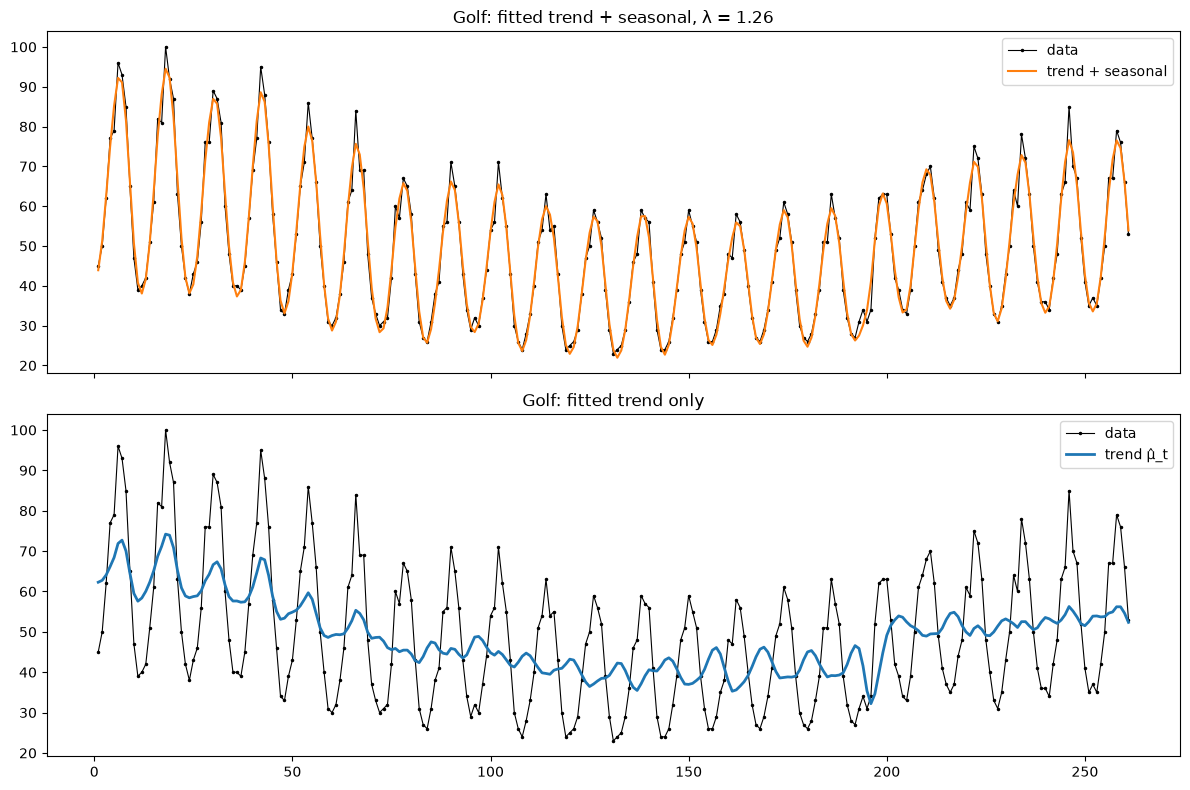

In [4]:
A = X.T @ X + best_lam * D
beta_best = np.linalg.solve(A, X.T @ y)

mu_best    = X[:, :N] @ beta_best[:N]      # trend only (mu_t)
seas_best  = X[:, N:] @ beta_best[N:]      # seasonal part
full_best  = mu_best + seas_best           # mu_t + seasonal

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
axes[0].plot(t, y, color='black', lw=0.8, marker='.', ms=3, label='data')
axes[0].plot(t, full_best, color='C1', lw=1.5, label='trend + seasonal')
axes[0].set_title(f'Golf: fitted trend + seasonal, λ = {best_lam:.3g}')
axes[0].legend()
axes[1].plot(t, y, color='black', lw=0.8, marker='.', ms=3, label='data')
axes[1].plot(t, mu_best, color='C0', lw=2, label='trend μ̂_t')
axes[1].set_title('Golf: fitted trend only')
axes[1].legend()
fig.tight_layout()
plt.show()

The model does a good job capturing the general trend but it struggle sto capture the full peaks of each period. However compared to the model from question 5 this model is able to capture the troughs. Also we see mu_t does a terrible job fitting the trend data alone without the seasonality.

Part B

i

In [5]:
n = len(y)
XtX = X.T @ X
Xty = X.T @ y
yty = y @ y

def log_post(tau, sigma):
    M = XtX / sigma**2 + D / tau**2
    try:
        L = np.linalg.cholesky(M)                  # M = L L^T
    except np.linalg.LinAlgError:
        return -np.inf
    logdet = 2 * np.sum(np.log(np.diag(L)))
    w = np.linalg.solve(L, Xty)                    # w @ w = Xty^T M^-1 Xty
    return (-(n - 2) * np.log(tau) - n * np.log(sigma)
            - 0.5 * logdet - 0.5 * (yty / sigma**2 - (w @ w) / sigma**4))

taus   = np.logspace(-3, 2, 61)
sigmas = np.logspace(-1, 1.5, 61)
LP = np.array([[log_post(ta, si) for si in sigmas] for ta in taus])

i, j = np.unravel_index(np.argmax(LP), LP.shape)
tau_hat, sigma_hat = taus[i], sigmas[j]
print(f"tau_hat = {tau_hat:.4g} (index {i}/{len(taus)-1}), sigma_hat = {sigma_hat:.4g} (index {j}/{len(sigmas)-1})")
print(f"sigma^2/tau^2 = {sigma_hat**2 / tau_hat**2:.4g}   vs   CV lambda = {best_lam:.4g}")
print("log-posterior around the peak (should change smoothly):")
print(np.round(LP[max(i-2,0):i+3, max(j-2,0):j+3] - LP[i, j], 2))


tau_hat = 0.03162 (index 18/60), sigma_hat = 4.642 (index 40/60)
sigma^2/tau^2 = 2.154e+04   vs   CV lambda = 1.259
log-posterior around the peak (should change smoothly):
[[-14.96  -4.88  -0.68  -1.35  -6.07]
 [-14.09  -4.23  -0.21  -1.02  -5.85]
 [-13.51  -3.86   0.    -0.94  -5.87]
 [-13.18  -3.73  -0.03  -1.09  -6.12]
 [-13.1   -3.84  -0.28  -1.46  -6.56]]


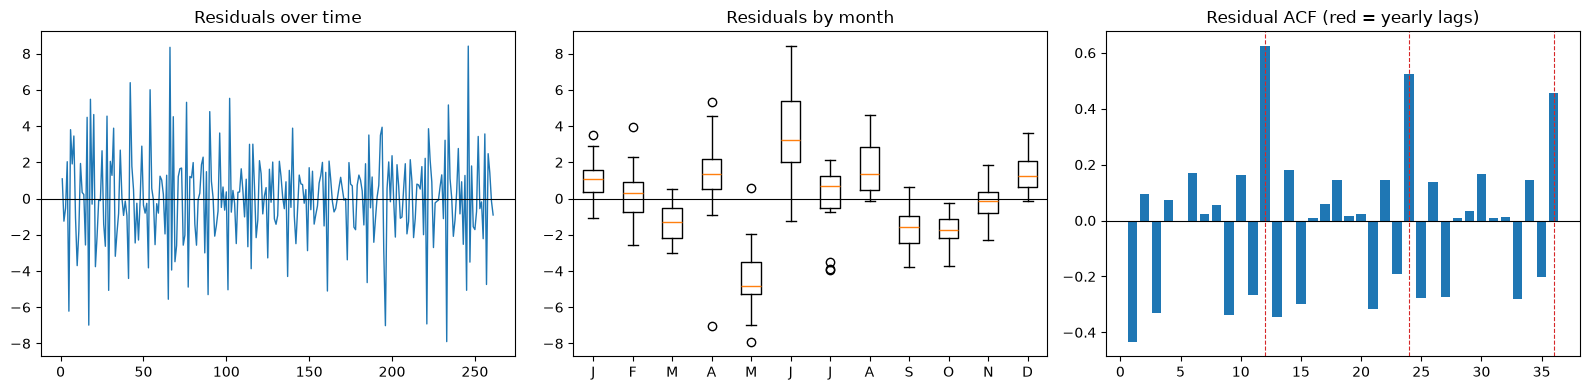

In [6]:
resid = y - full_best
month = (np.arange(n) % 12) + 1      

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(t, resid, lw=1)
axes[0].axhline(0, color='k', lw=0.8)
axes[0].set_title('Residuals over time')

axes[1].boxplot([resid[month == m] for m in range(1, 13)])
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(list('JFMAMJJASOND'))
axes[1].axhline(0, color='k', lw=0.8)
axes[1].set_title('Residuals by month')

lags = np.arange(1, 37)
r = resid - resid.mean()
acf = [np.sum(r[:-k] * r[k:]) / np.sum(r**2) for k in lags]
axes[2].bar(lags, acf)
axes[2].axhline(0, color='k', lw=0.8)
for k in (12, 24, 36):
    axes[2].axvline(k, color='C3', ls='--', lw=0.8)
axes[2].set_title('Residual ACF (red = yearly lags)')
fig.tight_layout(); plt.show()

ii

avg posterior sd of mu_t: 0.9008926262778574


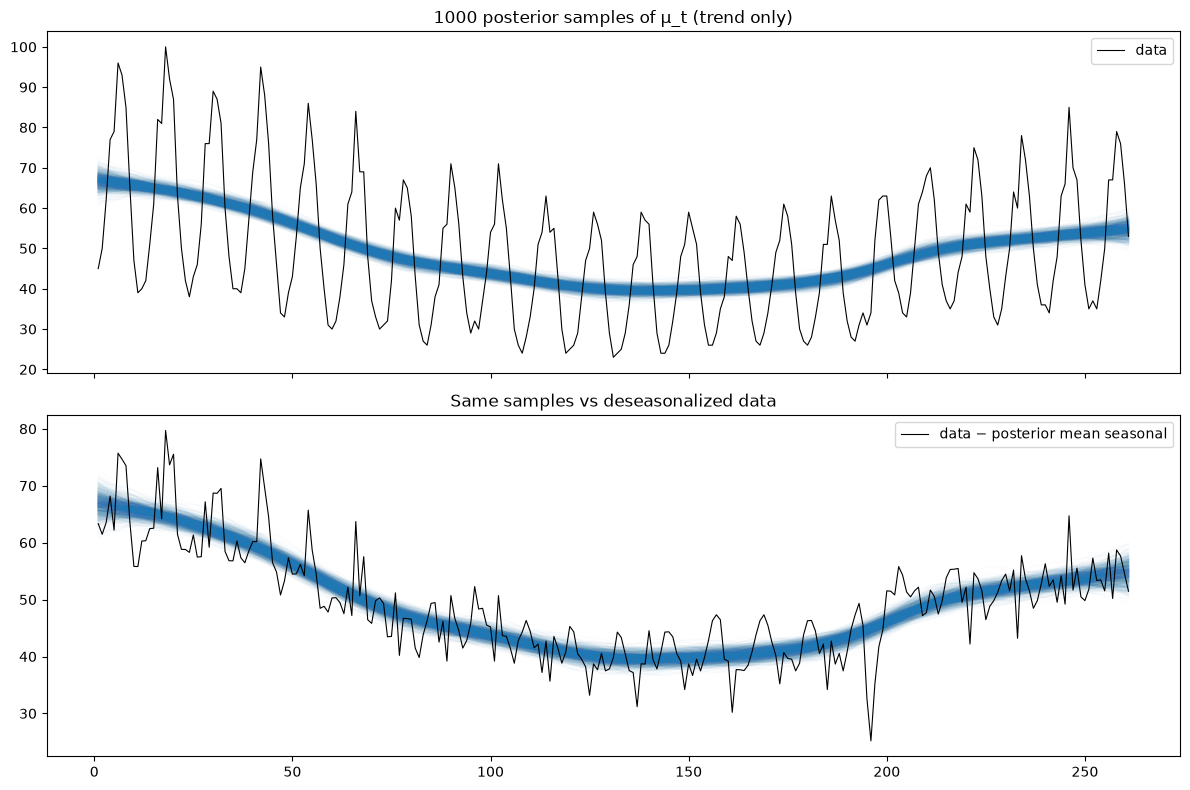

In [7]:
rng = np.random.default_rng(0)
Nsamp = 1000
p = N + 2


P = np.exp(LP - LP.max())
P /= P.sum()
flat = rng.choice(P.size, size=Nsamp, p=P.ravel())
ti, si = np.unravel_index(flat, P.shape)


mu_samples   = np.empty((Nsamp, N))
seas_samples = np.empty((Nsamp, N))
mu_condmean  = np.empty((Nsamp, N))
for s in range(Nsamp):
    tau, sigma = taus[ti[s]], sigmas[si[s]]
    M = XtX / sigma**2 + D / tau**2
    L = np.linalg.cholesky(M)
    mean = np.linalg.solve(L.T, np.linalg.solve(L, Xty / sigma**2))
    beta = mean + np.linalg.solve(L.T, rng.standard_normal(p))   

    mu_condmean[s]  = X[:, :N] @ mean[:N]      
    mu_samples[s]   = X[:, :N] @ beta[:N]    
    seas_samples[s] = X[:, N:] @ beta[N:]    

print("avg posterior sd of mu_t:", mu_samples.std(axis=0).mean())

# 3. plot
y_deseas = y - seas_samples.mean(axis=0)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, data, lab in [(axes[0], y, 'data'), (axes[1], y_deseas, 'data − posterior mean seasonal')]:
    ax.plot(t, data, color='black', lw=0.8, label=lab, zorder=3)
    for s in range(Nsamp):
        ax.plot(t, mu_samples[s], color='C0', alpha=0.02, lw=1)
    ax.legend()
axes[0].set_title('1000 posterior samples of μ_t (trend only)')
axes[1].set_title('Same samples vs deseasonalized data')
fig.tight_layout(); plt.show()


The posterier seems to follow teh trend far more and does seem to be phased about the swings. It does a good job capturing the trend and movement of the time series.

iii

roughness  ridge (a):         477.2
roughness  Bayesian estimate: 0.008593


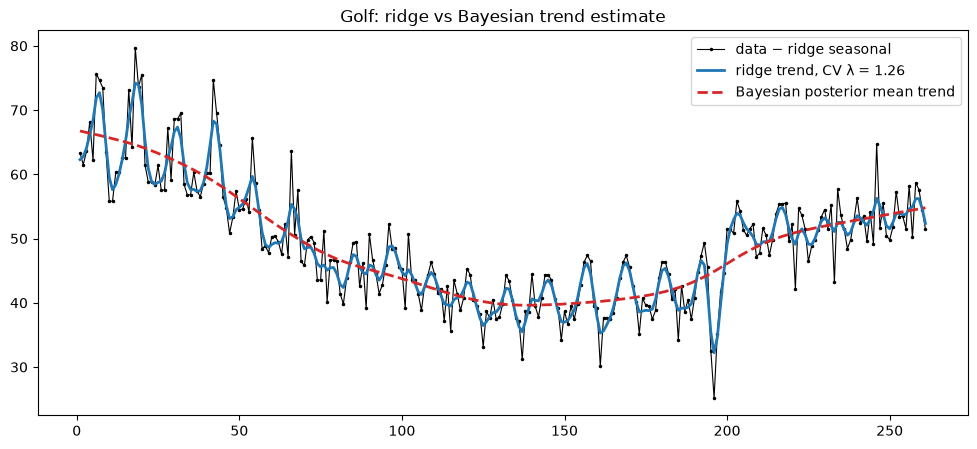

In [8]:
mu_bayes = mu_condmean.mean(axis=0)        # Bayesian point estimate of mu_t
mu_ridge = mu_best                         # ridge trend from part (a)

rough = lambda m: np.sum(np.diff(m, 2)**2)  # smaller = smoother
print(f"roughness  ridge (a):         {rough(mu_ridge):.4g}")
print(f"roughness  Bayesian estimate: {rough(mu_bayes):.4g}")

plt.figure(figsize=(12, 5))
plt.plot(t, y - seas_best, color='black', lw=0.8, marker='.', ms=3, label='data − ridge seasonal')
plt.plot(t, mu_ridge, color='C0', lw=2, label=f'ridge trend, CV λ = {best_lam:.3g}')
plt.plot(t, mu_bayes, color='C3', lw=2, ls='--', label='Bayesian posterior mean trend')
plt.title('Golf: ridge vs Bayesian trend estimate')
plt.legend()
plt.show()

The Bayesian estimate is much smoother than the ridge estimate. The ridge trend chases month to month noise and leftover seasonality, while the Bayesian trend shows the long-run pattern: a decline until the mid 2010s and a rise after 2020. I prefer the Bayesian estimate because it better captures the actual trend.